# In silico peptide digestion

Enumerate the products of trypsin cleavage in a short invented sequence.

Track the cut positions before forming peptides. A missed cleavage joins adjacent products. The common trypsin rule cuts after K or R unless the next residue is P. This exercise uses the unmodified sequence and the conventional rule.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from peptide_methods import digest

## Work through the data

The calculation prints its numerical result and plots the observations that produced it.

start  end  peptide
    0    3  AGK
    0   10  AGKTPRPAQK
    3   10  TPRPAQK
    3   13  TPRPAQKVLR
   10   13  VLR
   10   14  VLRT
   13   14  T


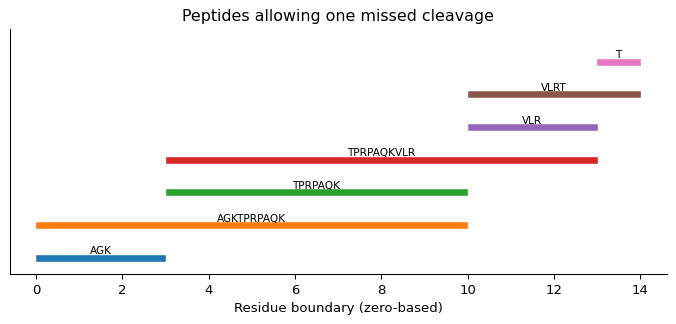

In [2]:
seq = "AGKTPRPAQKVLRT"
rows = digest(seq, 1)
print("start  end  peptide")
for a, b, s in rows:
    print(f"{a:5d}{b:5d}  {s}")
assert "".join(s for _, _, s in digest(seq)) == seq and "TPRPAQK" in [s for _, _, s in rows]
fig, ax = plt.subplots(figsize=(7, 3.3), constrained_layout=True)
for j, (a, b, s) in enumerate(rows):
    ax.plot([a + 0.08, b - 0.08], [j, j], lw=5)
    ax.text((a + b) / 2, j + 0.12, s, ha="center", fontsize=8)
ax.set(
    xlabel="Residue boundary (zero-based)",
    yticks=[],
    ylim=(-0.5, len(rows)),
    title="Peptides allowing one missed cleavage",
)
plt.show()

## Interpreting the result

The R followed by P stays inside its peptide. Longer lines span two products of a complete digest.

## Exercise

Change the residue immediately after the internal R and compare the cut sites.

## References

[ExPASy PeptideCutter, cleavage rules](https://web.expasy.org/peptide_cutter/peptidecutter_enzymes.html)